# Load Dataset


In [2]:
import pandas as pd

file_path = '../data/Online Budget Hotel Dataset.xlsx'

property_grade = pd.read_excel(file_path, sheet_name='Property Grade - For Reference')
bookings_table = pd.read_excel(file_path, sheet_name='Bookings Table')
user_table = pd.read_excel(file_path, sheet_name='User Table')
property_table = pd.read_excel(file_path, sheet_name='Property Table')


In [3]:
property_grade

,Monthly Occupancy Percentage,Grade
0,Monthly_occupancy > 80%,A
1,Monthly_occupancy between 70%> & < 80%,B
2,Monthly_occupancy between 40%> & < 70%,C
3,Monthly_occupancy between 20%> & < 40%,D
4,Monthly_occupancy < 20%,E


In [4]:
bookings_table.head()

,BOOKING_ID,USER_ID,PROPERTY_CODE,BOOKING_DATE,CHECK_IN_DATE,CHECK_OUT_DATE,ROOMS,NIGHTS,ROOM_NIGHTS,REVENUE_DOLLAR
0,942481721995472,2382984,MAL0084,2024-04-19,2024-04-19,2024-04-20,2,1,2,15.03
1,859896400600792,8922581,SUR0320,2024-07-21,2024-07-22,2024-07-23,3,1,3,14.85
2,863313142099180,11027905,SUR0381,2021-05-29,2021-06-05,2021-06-06,1,1,1,17.88
3,815705055066134,6964446,BAN0082,2022-03-31,2022-04-05,2022-04-07,1,3,3,27.92
4,257574986800513,1387674,BAN0482,2021-06-08,2021-06-14,2021-06-17,1,2,2,22.57


In [5]:
user_table.head()

,USER_ID,USER_TYPE,USER_GENDER,TRAVEL_PURPOSE,USER_AGE
0,9860949,New User,Female,Business,47
1,14615261,New User,Female,Leisure,28
2,7663712,New User,Female,Leisure,56
3,14003021,Repeat User,Male,Leisure,20
4,9689090,New User,Male,Leisure,33


In [6]:
property_table.head()

,PROPERTY_CODE,CITY,DISTRICT,COHORT_DATE,BRAND_TYPE,INVENTORY
0,YOG0000,Yogyakarta,Central,2022-04-12,Koolkost,31
1,MAL0001,Malang,North,2023-12-31,RedDoorz,80
2,BAN0002,Bandung,East,2020-06-11,RedPartner,58
3,SUR0003,Surabaya,North,2024-05-02,RedDoorz,95
4,JAK0004,Jakarta,West,2024-05-30,RedDoorz,72


# Data Quality Check

In [7]:
def quick_check(df, name):
    print(f"======================================")
    print(f" {name}")
    print(f"======================================")
    print(f"Dimensi (Baris, Kolom): {df.shape}")
    print(f"Total Missing Values   : {df.isna().sum().sum()}")
    print(f"Total Baris Duplikat   : {df.duplicated().sum()}")
    print("\nTipe Data per Kolom:")
    print(df.dtypes)
    print("\n")

In [8]:
quick_check(bookings_table, "Bookings Table")
quick_check(user_table, "User Table")
quick_check(property_table, "Property Table")

 Bookings Table
Dimensi (Baris, Kolom): (100000, 10)
Total Missing Values   : 0
Total Baris Duplikat   : 0

Tipe Data per Kolom:
BOOKING_ID                 int64
USER_ID                    int64
PROPERTY_CODE                str
BOOKING_DATE      datetime64[us]
CHECK_IN_DATE     datetime64[us]
CHECK_OUT_DATE    datetime64[us]
ROOMS                      int64
NIGHTS                     int64
ROOM_NIGHTS                int64
REVENUE_DOLLAR           float64
dtype: object


 User Table
Dimensi (Baris, Kolom): (1000, 5)
Total Missing Values   : 0
Total Baris Duplikat   : 0

Tipe Data per Kolom:
USER_ID           int64
USER_TYPE           str
USER_GENDER         str
TRAVEL_PURPOSE      str
USER_AGE          int64
dtype: object


 Property Table
Dimensi (Baris, Kolom): (500, 6)
Total Missing Values   : 0
Total Baris Duplikat   : 0

Tipe Data per Kolom:
PROPERTY_CODE               str
CITY                        str
DISTRICT                    str
COHORT_DATE      datetime64[us]
BRAND_TYPE    

In [9]:
# Cek ringkasan statistik untuk Bookings Table
print("=== Statistik Bookings Table ===")
print(bookings_table[['ROOMS', 'NIGHTS', 'ROOM_NIGHTS', 'REVENUE_DOLLAR']].describe())

# Cek ringkasan untuk User Table
print("\n=== Statistik User Table ===")
print(user_table[['USER_AGE']].describe())

=== Statistik Bookings Table ===
               ROOMS        NIGHTS    ROOM_NIGHTS  REVENUE_DOLLAR
count  100000.000000  100000.00000  100000.000000   100000.000000
mean        2.004970       1.99952       4.006390       20.011299
std         0.816867       0.81679       2.403129        5.779805
min         1.000000       1.00000       1.000000       10.000000
25%         1.000000       1.00000       2.000000       15.000000
50%         2.000000       2.00000       3.000000       20.020000
75%         3.000000       3.00000       6.000000       25.020000
max         3.000000       3.00000       9.000000       30.000000

=== Statistik User Table ===
          USER_AGE
count  1000.000000
mean     39.830000
std      11.902049
min      20.000000
25%      29.000000
50%      40.000000
75%      50.000000
max      60.000000


In [10]:
# Cek kategori unik di User Table
print("=== USER TABLE CATEGORIES ===")
print("User Type:", user_table['USER_TYPE'].unique())
print("User Gender:", user_table['USER_GENDER'].unique())
print("Travel Purpose:", user_table['TRAVEL_PURPOSE'].unique())

# Cek kategori unik di Property Table
print("\n=== PROPERTY TABLE CATEGORIES ===")
print("Kota:", property_table['CITY'].unique())
print("District", property_table['DISTRICT'].unique())
print("Brand Type:", property_table['BRAND_TYPE'].unique())

=== USER TABLE CATEGORIES ===
User Type: <StringArray>
['New User', 'Repeat User']
Length: 2, dtype: str
User Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Travel Purpose: <StringArray>
['Business', 'Leisure']
Length: 2, dtype: str

=== PROPERTY TABLE CATEGORIES ===
Kota: <StringArray>
['Yogyakarta', 'Malang', 'Bandung', 'Surabaya', 'Jakarta']
Length: 5, dtype: str
District <StringArray>
['Central', 'North', 'East', 'West', 'South']
Length: 5, dtype: str
Brand Type: <StringArray>
['Koolkost', 'RedDoorz', 'RedPartner']
Length: 3, dtype: str


# Eploratory Data Analysis (EDA)


## Extracting New Features from Booking Data (Stay Duration and Lead Time)


In [11]:
# Menambah fitur stay duration
bookings_table['STAY_DURATION'] = (bookings_table['CHECK_OUT_DATE'] - bookings_table['CHECK_IN_DATE']).dt.days

# Menambah fitur lead time
bookings_table['LEAD_TIME'] = (bookings_table['CHECK_IN_DATE'] - bookings_table['BOOKING_DATE']).dt.days

In [12]:
bookings_table.head()

,BOOKING_ID,USER_ID,PROPERTY_CODE,BOOKING_DATE,CHECK_IN_DATE,CHECK_OUT_DATE,ROOMS,NIGHTS,ROOM_NIGHTS,REVENUE_DOLLAR,STAY_DURATION,LEAD_TIME
0,942481721995472,2382984,MAL0084,2024-04-19,2024-04-19,2024-04-20,2,1,2,15.03,1,0
1,859896400600792,8922581,SUR0320,2024-07-21,2024-07-22,2024-07-23,3,1,3,14.85,1,1
2,863313142099180,11027905,SUR0381,2021-05-29,2021-06-05,2021-06-06,1,1,1,17.88,1,7
3,815705055066134,6964446,BAN0082,2022-03-31,2022-04-05,2022-04-07,1,3,3,27.92,2,5
4,257574986800513,1387674,BAN0482,2021-06-08,2021-06-14,2021-06-17,1,2,2,22.57,3,6


## Data Distribution for Stay Duration and Lead Time 

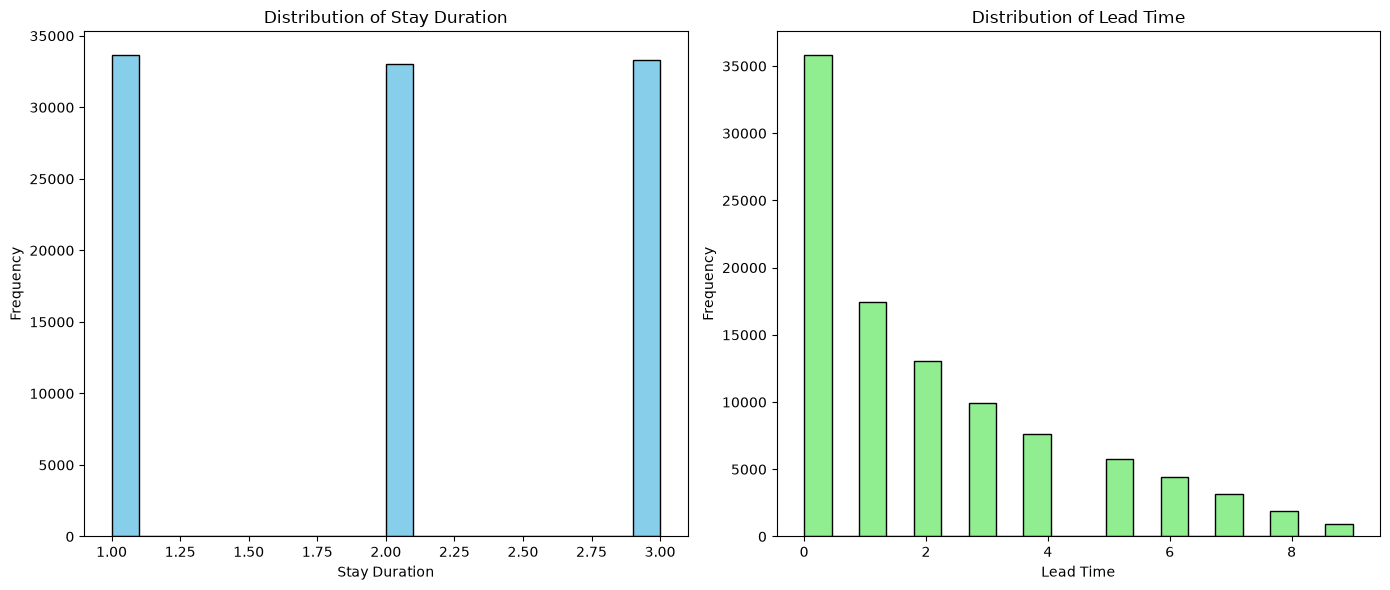

In [13]:
import matplotlib.pyplot as plt

fig, (axes1, axes2) = plt.subplots(1, 2, figsize=(14, 6))

axes1.hist(bookings_table['STAY_DURATION'], bins=20, color='skyblue', edgecolor='black')
axes1.set_title('Distribution of Stay Duration')
axes1.set_xlabel('Stay Duration')
axes1.set_ylabel('Frequency')

axes2.hist(bookings_table['LEAD_TIME'], bins=20, color='lightgreen', edgecolor='black')
axes2.set_title('Distribution of Lead Time')
axes2.set_xlabel('Lead Time')
axes2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Berdasarkan hasil visualisasi di atas, berikut adalah interpretasi distribusi dari masing masing fitur:

Stay Duration <br>
* Berdasarkan hasil visualisasi, durasi menginap pelanggan cenderung singkat, yakni 1-3 hari.
* Berdasarkan durasi menginap pelanggan yang singkat, tujuan pelanggan menginap di hotel-hotel milik Reddoorz kemungkinan adalah untuk transit atau perjalanan singkat. <br>

Lead Time <br>
* Hasil visualisasi menunjukkan bahwa pelanggan cenderung melakukan booking dengan waktu yang sangat dekat dengan tanggal check-in.
* Kebanyakan dari pelanggan melakukan booking pada hari mereka akan melakukan check-in.
* Hal tersebut kemungkinan karena keputusan mendadak dan kebutuhan mendesak dari pelanggan.










## Correlation between Stay Duration to Revenue, Lead Time to Revenue, and Stay Duration to Lead Time

In [14]:
stay_duration_and_revenue_cor = bookings_table['STAY_DURATION'].corr(bookings_table['REVENUE_DOLLAR'])
lead_time_and_revenue_cor = bookings_table['LEAD_TIME'].corr(bookings_table['REVENUE_DOLLAR'])
stay_duration_and_lead_time_cor = bookings_table['STAY_DURATION'].corr(bookings_table['LEAD_TIME'])

print(f"Correlation between Stay Duration and Revenue: {stay_duration_and_revenue_cor:.4f}")
print(f"Correlation between Lead Time and Revenue: {lead_time_and_revenue_cor:.4f}")
print(f"Correlation between Stay Duration and Lead Time: {stay_duration_and_lead_time_cor:.4f}")

Correlation between Stay Duration and Revenue: -0.0085
Correlation between Lead Time and Revenue: 0.0061
Correlation between Stay Duration and Lead Time: -0.0010


## Extracting New Features from Booking Data (Revenue per Night and Total Booking Revenue)

In [15]:
bookings_table['REVENUE_PER_NIGHT'] = bookings_table['REVENUE_DOLLAR']/bookings_table['ROOM_NIGHTS']

In [16]:
total_booking_revenue = bookings_table.groupby('USER_ID').agg({'REVENUE_DOLLAR':'sum'}).sort_values(by = 'REVENUE_DOLLAR', ascending=False).reset_index()

## Top 10 Costumers in Terms of Total Booking Revenue

In [17]:
top_10_cust_revenue = total_booking_revenue.head(10)
top_10_cust_revenue = top_10_cust_revenue.merge(user_table, on='USER_ID', how='left')
top_10_cust_revenue

,USER_ID,REVENUE_DOLLAR,USER_TYPE,USER_GENDER,TRAVEL_PURPOSE,USER_AGE
0,6534621,2708.86,New User,Female,Business,58
1,7818238,2651.86,Repeat User,Female,Business,47
2,6742780,2596.37,New User,Male,Business,20
3,2797960,2584.47,Repeat User,Male,Leisure,29
4,1060239,2548.25,New User,Male,Business,52
5,1066789,2545.37,Repeat User,Female,Business,58
6,1387674,2544.78,New User,Male,Leisure,47
7,1654979,2530.24,Repeat User,Male,Leisure,53
8,9726170,2524.71,Repeat User,Male,Business,40
9,3711707,2523.20,New User,Female,Leisure,40


## Extracting New Features (Property Occupancy Rate and Total Revenue per Property)

In [18]:
# Mencari last check in date untuk setiap property
last_check_in_date = bookings_table.groupby('PROPERTY_CODE').agg({'CHECK_IN_DATE': 'max'}).reset_index()
property_table = property_table.merge(last_check_in_date, on='PROPERTY_CODE', how='left')
property_table.rename(columns={'CHECK_IN_DATE': 'LAST_CHECK_IN_DATE'}, inplace=True)

C:\Users\krisn\AppData\Local\Temp\ipykernel_19884\3493590798.py:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  property_table.rename(columns={'CHECK_IN_DATE': 'LAST_CHECK_IN_DATE'}, inplace=True)


In [19]:
# Menghitung days active untuk setiap property (tanggal terakhir check in untuk setiap property - tanggal awal property terdaftar)
property_table['DAYS_ACTIVE'] = (property_table['LAST_CHECK_IN_DATE'] - property_table['COHORT_DATE']).dt.days

In [20]:
# Mencari total room night booked
filtered_bookings = bookings_table.merge(property_table[['PROPERTY_CODE', 'COHORT_DATE']], on='PROPERTY_CODE', how='left')
filtered_bookings = filtered_bookings[filtered_bookings['CHECK_IN_DATE'] >= filtered_bookings['COHORT_DATE']]

total_room_night_booked = filtered_bookings.groupby('PROPERTY_CODE').agg({'ROOM_NIGHTS': 'sum'}).reset_index()

property_table = property_table.merge(total_room_night_booked, on='PROPERTY_CODE', how='left')
property_table.rename(columns={'ROOM_NIGHTS': 'TOTAL_RNs'}, inplace=True)


C:\Users\krisn\AppData\Local\Temp\ipykernel_19884\24539480.py:8: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  property_table.rename(columns={'ROOM_NIGHTS': 'TOTAL_RNs'}, inplace=True)


In [21]:
# Menghitung occupancy rate untuk setiap property dari property awal terdaftar sampai tanggal check in terakhir
property_table['OCCUPANCY_RATE_(%)'] = (property_table['TOTAL_RNs']/(property_table['INVENTORY']*property_table['DAYS_ACTIVE']))*100

In [22]:
# Menghitung total revenue untuk setiap property (dari tanggal awal terdaftar)
filtered_revenue = bookings_table.merge(property_table[['PROPERTY_CODE', 'COHORT_DATE']], on='PROPERTY_CODE', how='left')
filtered_revenue = filtered_revenue[filtered_revenue['CHECK_IN_DATE'] >= filtered_revenue['COHORT_DATE']]

total_revenue_per_property = filtered_revenue.groupby('PROPERTY_CODE').agg({'REVENUE_DOLLAR':'sum'}).reset_index()
property_table = property_table.merge(total_revenue_per_property, on='PROPERTY_CODE', how='left')
property_table.rename(columns={'REVENUE_DOLLAR': 'TOTAL_REVENUE_DOLLAR'}, inplace=True)

C:\Users\krisn\AppData\Local\Temp\ipykernel_19884\1526857614.py:7: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  property_table.rename(columns={'REVENUE_DOLLAR': 'TOTAL_REVENUE_DOLLAR'}, inplace=True)


In [23]:
property_table

,PROPERTY_CODE,CITY,DISTRICT,COHORT_DATE,BRAND_TYPE,INVENTORY,LAST_CHECK_IN_DATE,DAYS_ACTIVE,TOTAL_RNs,OCCUPANCY_RATE_(%),TOTAL_REVENUE_DOLLAR
0,YOG0000,Yogyakarta,Central,2022-04-12,Koolkost,31,2024-09-29,901,417.0,1.492965,2096.31
1,MAL0001,Malang,North,2023-12-31,RedDoorz,80,2024-09-26,270,126.0,0.583333,583.20
2,BAN0002,Bandung,East,2020-06-11,RedPartner,58,2024-09-30,1572,841.0,0.922392,4316.36
3,SUR0003,Surabaya,North,2024-05-02,RedDoorz,95,2024-09-26,147,61.0,0.436806,306.08
4,JAK0004,Jakarta,West,2024-05-30,RedDoorz,72,2024-08-28,90,55.0,0.848765,257.01
...,...,...,...,...,...,...,...,...,...,...,...
495,YOG0495,Yogyakarta,South,2020-07-03,RedDoorz,67,2024-09-29,1549,689.0,0.663885,3498.16
496,YOG0496,Yogyakarta,South,2020-09-05,RedDoorz,57,2024-09-18,1474,623.0,0.741508,3089.58
497,SUR0497,Surabaya,East,2021-05-02,RedPartner,96,2024-09-30,1247,586.0,0.489508,2835.64
498,BAN0498,Bandung,Central,2020-06-06,RedDoorz,28,2024-09-25,1572,754.0,1.713013,3612.60


In [24]:
# Pengecekan Nilai NaN
property_table.isna().sum()

PROPERTY_CODE           0
CITY                    0
DISTRICT                0
COHORT_DATE             0
BRAND_TYPE              0
INVENTORY               0
LAST_CHECK_IN_DATE      0
DAYS_ACTIVE             0
TOTAL_RNs               1
OCCUPANCY_RATE_(%)      1
TOTAL_REVENUE_DOLLAR    1
dtype: int64

In [25]:
# Menampilkan baris di property_table yang kolom TOTAL_RNs-nya bernilai NaN (kosong)
missing_property = property_table[property_table['TOTAL_RNs'].isna()]

missing_property

,PROPERTY_CODE,CITY,DISTRICT,COHORT_DATE,BRAND_TYPE,INVENTORY,LAST_CHECK_IN_DATE,DAYS_ACTIVE,TOTAL_RNs,OCCUPANCY_RATE_(%),TOTAL_REVENUE_DOLLAR
331,JAK0331,Jakarta,North,2024-09-28,RedPartner,33,2024-09-18,-10,NaN,NaN,NaN


In [26]:
# Mengisi nilai NaN dengan nilai 0
property_table = property_table.fillna(0)

## Top 10 Properties with the Highest Occupancy Rate

In [27]:
top_10_properties = property_table.groupby('PROPERTY_CODE').agg({'OCCUPANCY_RATE_(%)': 'sum'}).sort_values(by='OCCUPANCY_RATE_(%)', ascending=False).reset_index()
top_10_properties = top_10_properties.head(10)
top_10_properties = top_10_properties.merge(property_table[['PROPERTY_CODE','CITY', 'COHORT_DATE', 'BRAND_TYPE', 'DAYS_ACTIVE', 'TOTAL_REVENUE_DOLLAR']], on='PROPERTY_CODE', how='left')
top_10_properties

,PROPERTY_CODE,OCCUPANCY_RATE_(%),CITY,COHORT_DATE,BRAND_TYPE,DAYS_ACTIVE,TOTAL_REVENUE_DOLLAR
0,YOG0484,6.521739,Yogyakarta,2024-09-22,RedPartner,2,32.73
1,JAK0471,3.658537,Jakarta,2024-09-25,Koolkost,2,21.97
2,BAN0192,2.796202,Bandung,2022-10-09,RedDoorz,699,2063.03
3,BAN0423,2.743902,Bandung,2024-05-31,RedPartner,123,346.44
4,BAN0229,2.576419,Bandung,2023-07-02,RedPartner,458,1158.63
5,BAN0428,2.500000,Bandung,2024-09-05,RedPartner,6,27.36
6,YOG0490,2.420382,Yogyakarta,2020-06-08,RedPartner,1570,4196.77
7,JAK0253,2.295918,Jakarta,2023-12-14,RedPartner,280,676.87
8,YOG0420,2.283042,Yogyakarta,2021-02-12,Koolkost,1322,3230.77
9,BAN0249,2.259922,Bandung,2022-12-27,RedDoorz,628,1710.43


## Correlation between Occupancy Rate and Total Revenue per Property



In [28]:
correlation = property_table['OCCUPANCY_RATE_(%)'].corr(property_table['TOTAL_REVENUE_DOLLAR'])
print(correlation)

-0.11194845194175937


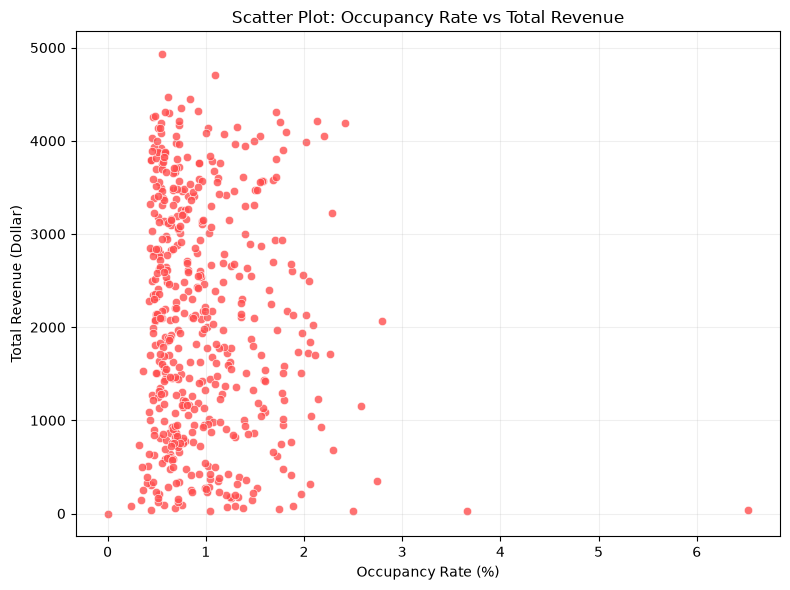

In [29]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x=property_table['OCCUPANCY_RATE_(%)'], y=property_table['TOTAL_REVENUE_DOLLAR'], color='#ff4d4d', alpha=0.8)

plt.title(f"Scatter Plot: Occupancy Rate vs Total Revenue")
plt.xlabel("Occupancy Rate (%)")
plt.ylabel("Total Revenue (Dollar)")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()
